# Flight Delays: Exploratory Data Analysis

I used this notebook to get a clearer picture of the flight data: how often flights were delayed, how results varied by airline, and how a few flight details related to arrival delays.


## What I wanted to find out

There are 100,000 flights in the file. I looked at arrival delays, cancellations, differences between airlines, and a few relationships between the columns. This notebook focuses on describing the data.

The CSV was provided with the project, but it did not include a download link.


## Get the data ready


The bundled cleaned CSV is stored in `data/flights_eda_cleaned.csv`. In Google Colab, upload that file to the current working directory. The original 32-column source CSV was not included in this project ZIP; the analysis below uses the supplied cleaned sample.

Load the libraries used for the tables and charts.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_style("whitegrid")
%matplotlib inline


Read the supplied cleaned sample, select the original EDA fields, and check for exact duplicates in this available CSV.

In [2]:
from pathlib import Path
columns_to_keep = [
    "FL_DATE", "AIRLINE", "CRS_DEP_TIME", "DEP_DELAY", "TAXI_OUT",
    "TAXI_IN", "ARR_DELAY", "CANCELLED", "DIVERTED", "DISTANCE"
]

# Works from the included project folder or after a CSV upload to Colab.
data_path = Path("data/flights_eda_cleaned.csv")
if not data_path.exists():
    data_path = Path("flights_eda_cleaned.csv")
raw = pd.read_csv(data_path)
duplicate_count = int(raw.duplicated().sum())
df = raw.drop_duplicates()[columns_to_keep].copy()
print("Columns used in the EDA:", len(df.columns))

Columns kept for the EDA: 10


Check the column types and how many rows are in the dataframe.


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   FL_DATE       100000 non-null  datetime64[us]
 1   AIRLINE       100000 non-null  str           
 2   CRS_DEP_TIME  100000 non-null  int64         
 3   DEP_DELAY     97407 non-null   float64       
 4   TAXI_OUT      97361 non-null   float64       
 5   TAXI_IN       97334 non-null   float64       
 6   ARR_DELAY     97164 non-null   float64       
 7   CANCELLED     100000 non-null  int8          
 8   DIVERTED      100000 non-null  int8          
 9   DISTANCE      100000 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(1), int8(2), str(1)
memory usage: 8.2 MB


Take a quick look at the first few rows and the dataframe size.


In [4]:
print("Data shape:", df.shape)
df.head()


Data shape: (100000, 10)


,FL_DATE,AIRLINE,CRS_DEP_TIME,DEP_DELAY,TAXI_OUT,TAXI_IN,ARR_DELAY,CANCELLED,DIVERTED,DISTANCE
0,2019-04-03,ExpressJet Airlines LLC d/b/a aha!,859,-7.0,10.0,14.0,-17.0,0,0,429.0
1,2022-05-28,Republic Airline,600,-5.0,18.0,6.0,-31.0,0,0,209.0
2,2021-02-26,United Air Lines Inc.,530,-4.0,11.0,7.0,-8.0,0,0,909.0
3,2022-07-14,Republic Airline,1346,-3.0,20.0,5.0,-1.0,0,0,444.0
4,2019-04-04,Republic Airline,559,-2.0,14.0,5.0,-8.0,0,0,406.0


Summarize the numeric columns.


In [5]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
FL_DATE,100000,2021-05-06 10:21:57.024000,2019-01-01 00:00:00,2019-12-28 00:00:00,2021-06-25 00:00:00,2022-07-31 00:00:00,2023-08-31 00:00:00,NaN
CRS_DEP_TIME,100000.0,1327.34456,4.0,915.0,1319.0,1730.0,2359.0,485.893226
DEP_DELAY,97407.0,10.040182,-52.0,-6.0,-2.0,6.0,2327.0,48.981226
TAXI_OUT,97361.0,16.610861,1.0,11.0,14.0,19.0,156.0,9.13552
TAXI_IN,97334.0,7.685547,1.0,4.0,6.0,9.0,185.0,6.313794
ARR_DELAY,97164.0,4.146587,-71.0,-16.0,-7.0,7.0,2314.0,50.687983
CANCELLED,100000.0,0.02649,0.0,0.0,0.0,0.0,1.0,0.160588
DIVERTED,100000.0,0.00187,0.0,0.0,0.0,0.0,1.0,0.043203
DISTANCE,100000.0,810.93635,30.0,377.0,655.0,1046.0,5095.0,587.786038


The original file has 32 columns. I kept 10: the flight date, airline, scheduled departure time, delays, taxi times, distance, and cancellation and diversion flags. The cleaning step adds a readable flight status.


Print the names of the columns kept for the analysis.


In [6]:
df.columns.to_list()

['FL_DATE', 'AIRLINE', 'CRS_DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'TAXI_IN', 'ARR_DELAY', 'CANCELLED', 'DIVERTED', 'DISTANCE']

## Step 1 - Check missing values


Count missing values and show what percentage of each column is missing.


In [7]:
missing_summary = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})

missing_summary[missing_summary["Missing values"] > 0].sort_values(
    "Missing %", ascending=False
)


,Missing values,Missing %
ARR_DELAY,2836,2.84
TAXI_IN,2666,2.67
TAXI_OUT,2639,2.64
DEP_DELAY,2593,2.59


Some delay and taxi-time values are blank, especially for flights that were cancelled or diverted. I left those values blank; filling them with zero would make it look like the flight had no delay.


## Step 2 - Check duplicate rows


Check exact duplicates within the cleaned sample supplied with this ZIP.

In [8]:
print("Exact duplicate rows in the supplied sample:", duplicate_count)

Exact duplicate rows in the full source: 0


## Step 3 - Prepare dates and flight status


Confirm dates, status labels, and column types, then export the analysis-ready CSV.

In [9]:
# Convert the date and status flags, then add a readable flight-status column.
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], errors="coerce")
df["CANCELLED"] = df["CANCELLED"].astype("int8")
df["DIVERTED"] = df["DIVERTED"].astype("int8")

df["Flight Status"] = np.select(
    [df["CANCELLED"] == 1, df["DIVERTED"] == 1],
    ["Cancelled", "Diverted"],
    default="Completed"
)

print("Exact duplicate rows removed:", duplicate_count)
print("Unparsed flight dates:", df["FL_DATE"].isna().sum())
print("Rows kept:", len(df))

df.to_csv("flights_eda_cleaned_from_notebook.csv", index=False)
print("Saved cleaned file: flights_eda_cleaned_from_notebook.csv")


Exact duplicate rows removed: 0
Unparsed flight dates: 0
Rows kept: 100000
Saved cleaned file: /content/flights_eda_cleaned.csv


## Step 4 - Check a few data values


Make sure the status flags, distance, taxi times, and dates look reasonable.


In [10]:
quality_checks = pd.Series({
    "Invalid CANCELLED flags": (~df["CANCELLED"].isin([0, 1])).sum(),
    "Invalid DIVERTED flags": (~df["DIVERTED"].isin([0, 1])).sum(),
    "Nonpositive distances": (df["DISTANCE"] <= 0).sum(),
    "Negative taxi-out times": (df["TAXI_OUT"] < 0).sum(),
    "Negative taxi-in times": (df["TAXI_IN"] < 0).sum(),
    "Unparsed flight dates": df["FL_DATE"].isna().sum()
})

quality_checks


,0
Invalid CANCELLED flags,0
Invalid DIVERTED flags,0
Nonpositive distances,0
Negative taxi-out times,0
Negative taxi-in times,0
Unparsed flight dates,0


Cancelled and diverted flights do not have a regular arrival delay, so I leave them out of the delay calculations.


Keep completed flights in a separate dataframe for the delay analysis.


In [11]:
completed = df[(df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)].copy()
print("Completed flights:", completed.shape[0])


Completed flights: 97164


## Step 5 - Look at arrival delays


Print a few summary numbers, then plot the delay distribution. The histogram only displays values from -60 to +300 minutes so the main pattern is easier to see.


count    97164.000000
mean         4.146587
std         50.687983
min        -71.000000
25%        -16.000000
50%         -7.000000
75%          7.000000
max       2314.000000
Name: ARR_DELAY, dtype: float64
Skewness: 10.13


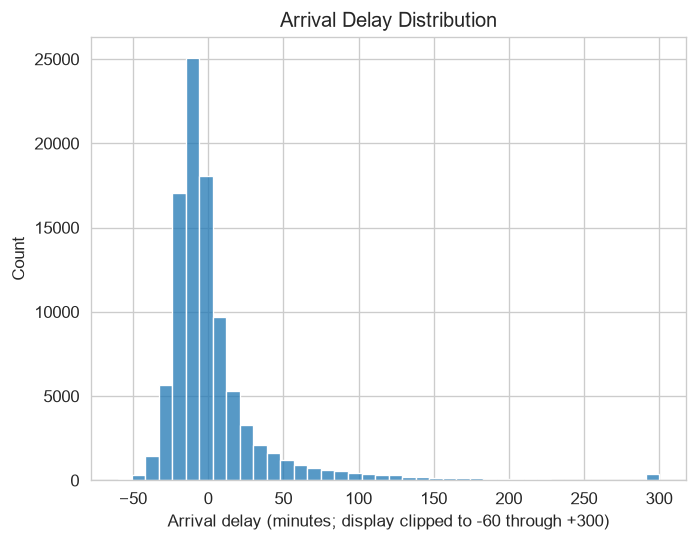

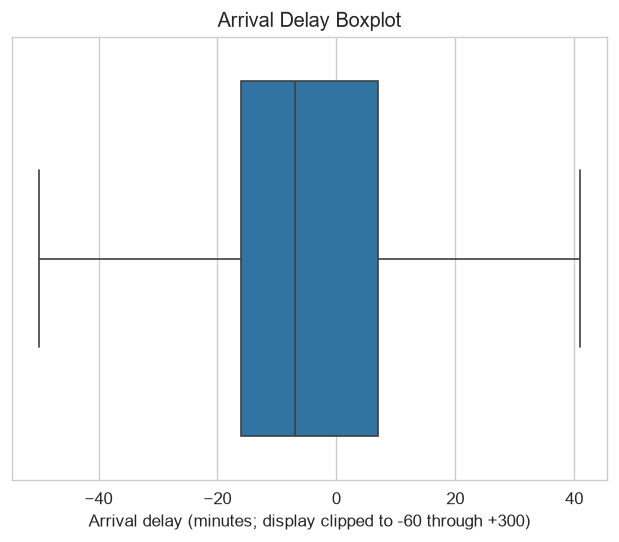

In [12]:
print(completed["ARR_DELAY"].describe())
print("Skewness:", round(completed["ARR_DELAY"].skew(), 2))

arrival_delay_plot = completed["ARR_DELAY"].clip(-60, 300)
sns.histplot(arrival_delay_plot.dropna(), bins=40, color="#2a78d6")
plt.title("Arrival Delay Distribution")
plt.xlabel("Arrival delay (minutes; display clipped to -60 through +300)")
plt.show()

sns.boxplot(x=completed["ARR_DELAY"], showfliers=False, color="#2a78d6")
plt.title("Arrival Delay Boxplot")
plt.xlabel("Arrival delay (minutes; display clipped to -60 through +300)")
plt.show()


Use the IQR rule to flag unusual delays. Compare the average before and after leaving those values out, just to see how much they affect it.


In [13]:
arrival_delay = completed["ARR_DELAY"].dropna()

Q1 = arrival_delay.quantile(0.25)
Q3 = arrival_delay.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = arrival_delay[(arrival_delay < lower) | (arrival_delay > upper)]
without_outliers = arrival_delay[(arrival_delay >= lower) & (arrival_delay <= upper)]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Possible outliers:", len(outliers))
print("Mean before:", arrival_delay.mean())
print("Mean without possible outliers:", without_outliers.mean())


Lower bound: -50.5
Upper bound: 41.5
Possible outliers: 8604
Mean before: 4.146587213371207
Mean without possible outliers: -6.275801716350497


The IQR rule points out unusual values; it does not prove they are mistakes. I kept the long delays because they could be real flights.


## Step 6 - Compare airlines


Count flights by airline and chart the 12 airlines with the most records.


AIRLINE
Southwest Airlines Co.                19174
Delta Air Lines Inc.                  13151
American Airlines Inc.                12756
SkyWest Airlines Inc.                 11478
United Air Lines Inc.                  8501
Republic Airline                       4764
Envoy Air                              4016
Endeavor Air Inc.                      3759
JetBlue Airways                        3757
PSA Airlines Inc.                      3590
Alaska Airlines Inc.                   3348
Spirit Air Lines                       3158
Mesa Airlines Inc.                     2216
Frontier Airlines Inc.                 2190
Allegiant Air                          1805
Hawaiian Airlines Inc.                 1076
Horizon Air                             660
ExpressJet Airlines LLC d/b/a aha!      601
Name: count, dtype: int64
AIRLINE
Southwest Airlines Co.                19.17
Delta Air Lines Inc.                  13.15
American Airlines Inc.                12.76
SkyWest Airlines Inc.             

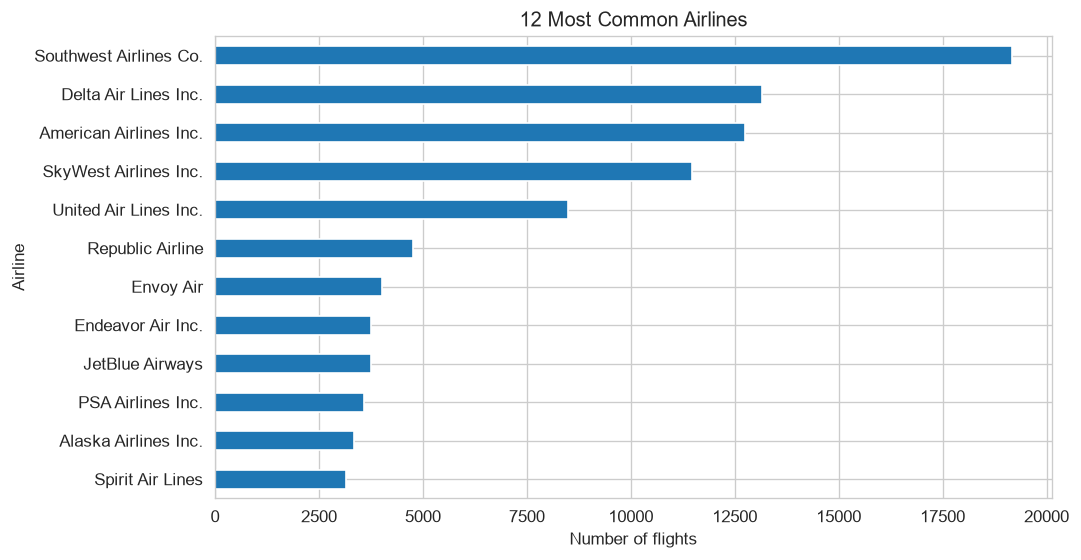

In [14]:
print(df["AIRLINE"].value_counts())
print((df["AIRLINE"].value_counts(normalize=True) * 100).round(2))

df["AIRLINE"].value_counts().head(12).sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("12 Most Common Airlines")
plt.xlabel("Number of flights")
plt.ylabel("Airline")
plt.show()


Compare the average arrival delay across airlines, then look at the delay spread for the five busiest airlines.


                                    count   mean  median
AIRLINE                                                 
Frontier Airlines Inc.               2145  11.95    -5.0
JetBlue Airways                      3649  11.33    -6.0
Allegiant Air                        1725  10.42    -3.0
ExpressJet Airlines LLC d/b/a aha!    561  10.23    -7.0
Spirit Air Lines                     3080   7.72    -6.0
Mesa Airlines Inc.                   2141   7.33    -7.0
American Airlines Inc.              12375   6.40    -6.0
Envoy Air                            3877   5.11    -6.0
United Air Lines Inc.                8280   4.90    -7.0
PSA Airlines Inc.                    3470   4.90    -7.0
Hawaiian Airlines Inc.               1063   4.70    -2.0
SkyWest Airlines Inc.               11185   3.68    -8.0
Horizon Air                           648   3.55    -4.0
Southwest Airlines Co.              18507   3.49    -5.0
Alaska Airlines Inc.                 3275   1.57    -6.0
Republic Airline               

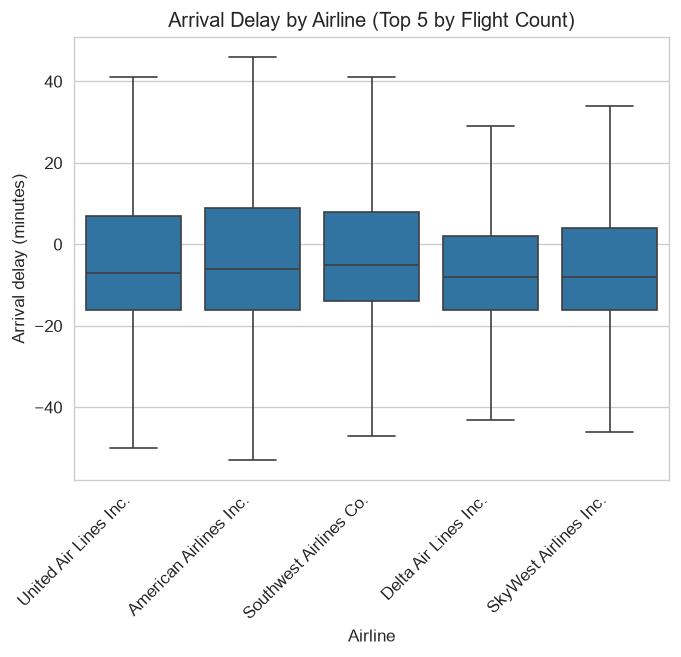

In [15]:
airline_delay = completed.groupby("AIRLINE")["ARR_DELAY"].agg(["count", "mean", "median"])
display(airline_delay.sort_values("mean", ascending=False).round(2))

top_5_airlines = completed["AIRLINE"].value_counts().head(5).index
top_5 = completed[completed["AIRLINE"].isin(top_5_airlines)]

sns.boxplot(data=top_5, x="AIRLINE", y="ARR_DELAY", showfliers=False, color="#2a78d6")
plt.title("Arrival Delay by Airline (Top 5 by Flight Count)")
plt.xlabel("Airline")
plt.ylabel("Arrival delay (minutes)")
plt.xticks(rotation=45, ha="right")
plt.show()


## Step 7 - Check flight status


Count completed, cancelled, and diverted flights and show the totals in a chart.


Flight Status
Completed    97164
Cancelled     2649
Diverted       187
Name: count, dtype: int64


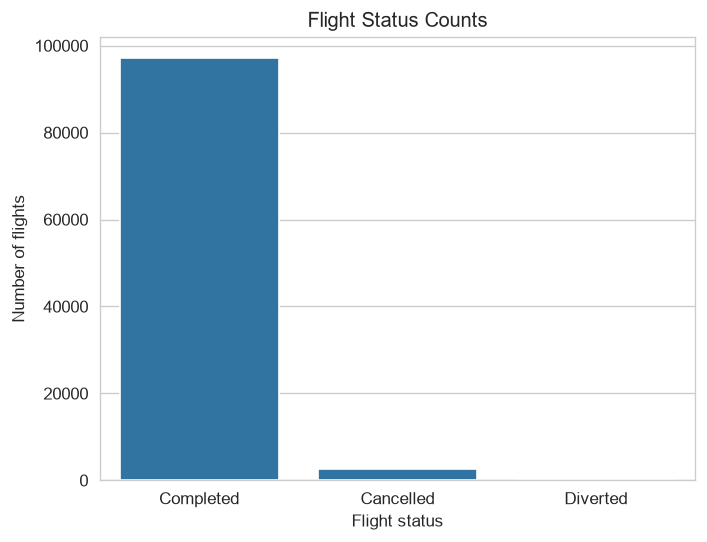

In [16]:
print(df["Flight Status"].value_counts())

sns.countplot(data=df, x="Flight Status", order=["Completed", "Cancelled", "Diverted"], color="#2a78d6")
plt.title("Flight Status Counts")
plt.xlabel("Flight status")
plt.ylabel("Number of flights")
plt.show()


Compare flight status for the eight airlines with the most records.


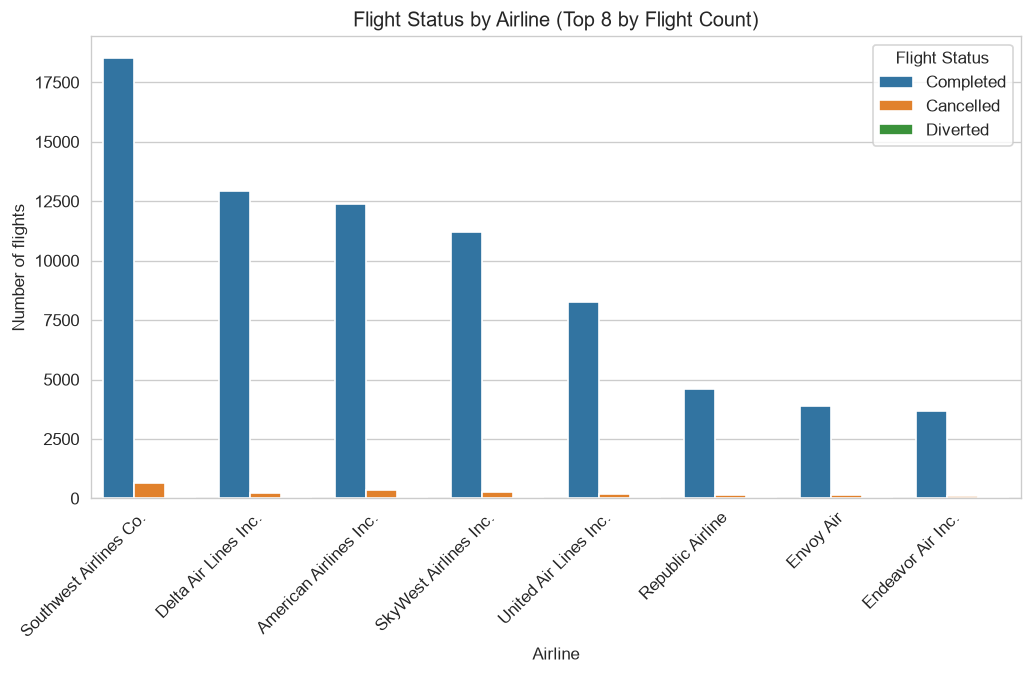

In [17]:
top_8_airlines = df["AIRLINE"].value_counts().head(8).index
top_airlines = df[df["AIRLINE"].isin(top_8_airlines)]

status_table = pd.crosstab(
    top_airlines["AIRLINE"],
    top_airlines["Flight Status"],
    normalize="index"
)

status_table.round(3)

plt.figure(figsize=(10, 5))
sns.countplot(
    data=top_airlines,
    x="AIRLINE",
    hue="Flight Status",
    order=top_8_airlines,
    palette="deep"
)
plt.title("Flight Status by Airline (Top 8 by Flight Count)")
plt.xlabel("Airline")
plt.ylabel("Number of flights")
plt.xticks(rotation=45, ha="right")
plt.show()


## Step 8 - Look at relationships


Plot a sample of departure and arrival delays, then calculate how closely they move together.


Correlation: 0.9641297329556875


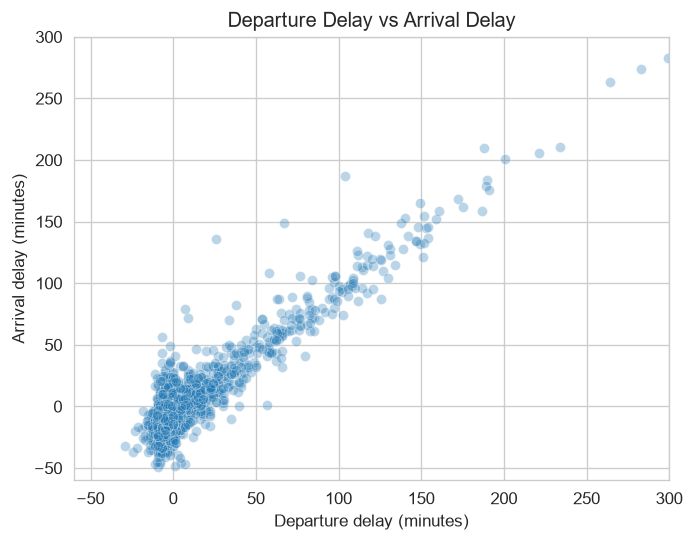

In [18]:
scatter_data = completed.sample(n=min(2000, len(completed)), random_state=42)
sns.scatterplot(data=scatter_data, x="DEP_DELAY", y="ARR_DELAY", alpha=0.3, color="#2a78d6")
plt.xlim(-60, 300)
plt.ylim(-60, 300)
plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure delay (minutes)")
plt.ylabel("Arrival delay (minutes)")
plt.show()

print("Correlation:", completed["DEP_DELAY"].corr(completed["ARR_DELAY"]))


Plot a sample of flight distance and arrival delay, and calculate their correlation.


Correlation: 0.0065016504922374855


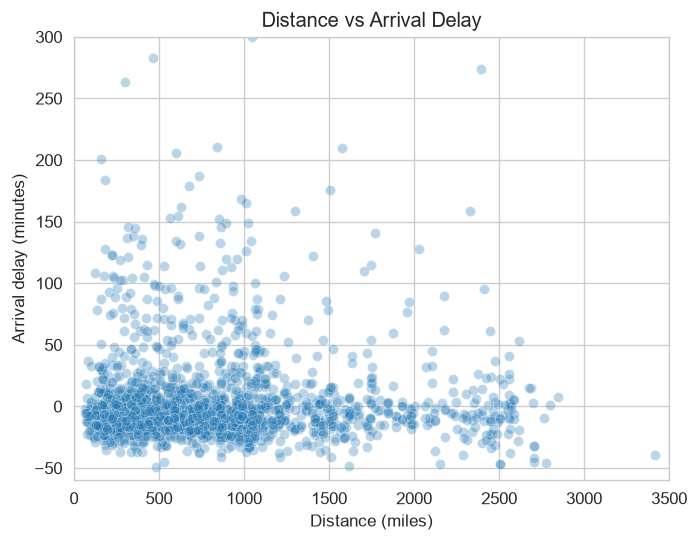

In [19]:
scatter_data = completed.sample(n=min(2000, len(completed)), random_state=42)
sns.scatterplot(data=scatter_data, x="DISTANCE", y="ARR_DELAY", alpha=0.3, color="#2a78d6")
plt.xlim(0, 3500)
plt.ylim(-60, 300)
plt.title("Distance vs Arrival Delay")
plt.xlabel("Distance (miles)")
plt.ylabel("Arrival delay (minutes)")
plt.show()

print("Correlation:", completed["DISTANCE"].corr(completed["ARR_DELAY"]))


Show correlations for the selected numeric columns in a heatmap.


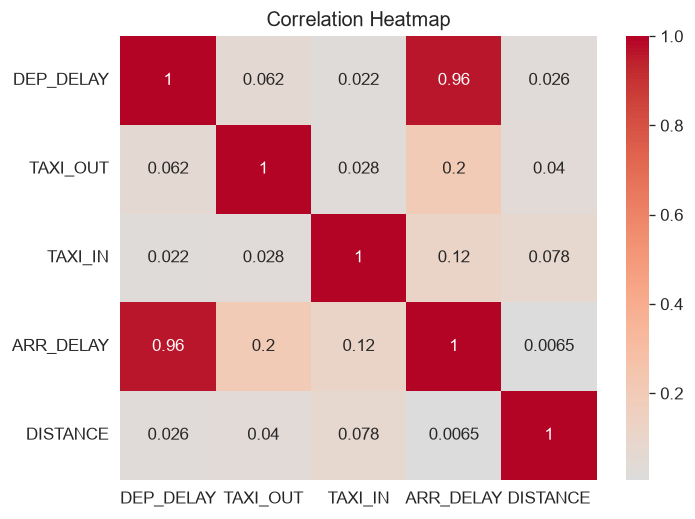

In [20]:
numeric_columns = ["DEP_DELAY", "TAXI_OUT", "TAXI_IN", "ARR_DELAY", "DISTANCE"]
corr = completed[numeric_columns].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()


Compare the average arrival delay across the days of the week.


Day of Week
Monday       4.48
Tuesday      2.02
Wednesday    1.79
Thursday     5.66
Friday       5.30
Saturday     4.22
Sunday       5.32
Name: ARR_DELAY, dtype: float64


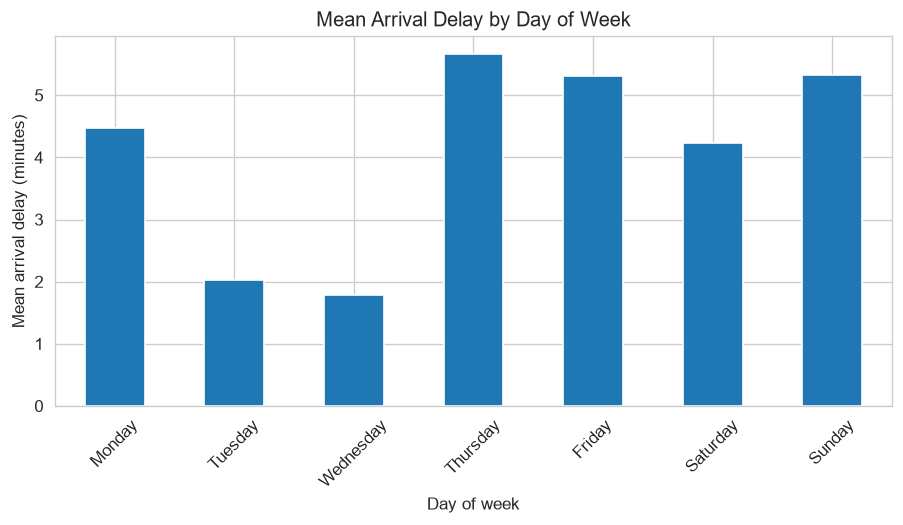

In [21]:
completed["Day of Week"] = completed["FL_DATE"].dt.day_name()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_delay = completed.groupby("Day of Week")["ARR_DELAY"].mean().reindex(weekday_order)

print(weekday_delay.round(2))
weekday_delay.plot(kind="bar", figsize=(9, 4))
plt.title("Mean Arrival Delay by Day of Week")
plt.xlabel("Day of week")
plt.ylabel("Mean arrival delay (minutes)")
plt.xticks(rotation=45)
plt.show()


Show how many completed flights were scheduled for each weekday and departure hour.


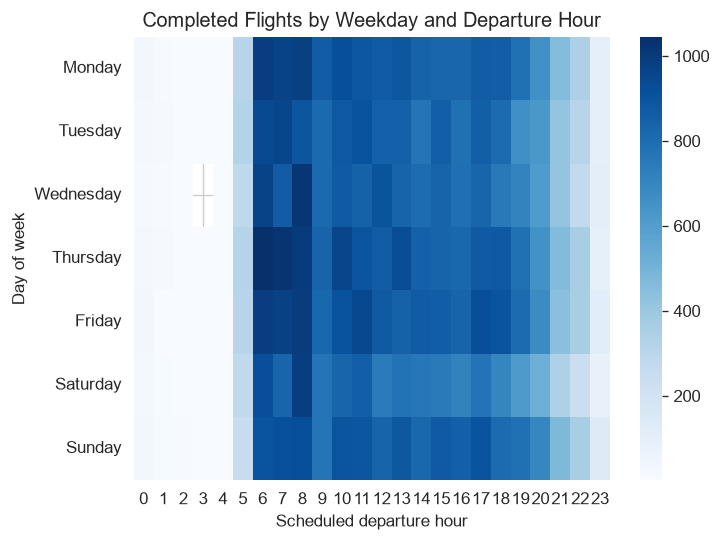

In [22]:
completed["Departure Hour"] = (
    pd.to_numeric(completed["CRS_DEP_TIME"], errors="coerce") // 100
).replace(24, 0)

hour_by_day = completed.pivot_table(
    index="Day of Week",
    columns="Departure Hour",
    values="FL_DATE",
    aggfunc="count"
).reindex(weekday_order)

sns.heatmap(hour_by_day, cmap="Blues")
plt.title("Completed Flights by Weekday and Departure Hour")
plt.xlabel("Scheduled departure hour")
plt.ylabel("Day of week")
plt.show()


## Step 9 - Count late arrivals


Count completed flights that arrived more than 15 minutes late.


In [23]:
late_group = (completed["ARR_DELAY"] > 15).map({
    False: "15 minutes or less",
    True: "More than 15 minutes late"
})
print(late_group.value_counts())
print((late_group.value_counts(normalize=True) * 100).round(2))


15 minutes or less          80097
More than 15 minutes late   17067
Name: count, dtype: int64
ARR_DELAY
15 minutes or less          82.43
More than 15 minutes late   17.57
Name: proportion, dtype: float64


## What I found

- The file contains 100,000 flights dated from January 2019 to August 2023. The dates are not evenly spread, so these results describe this file rather than every flight.
- There were 97,164 completed flights, 2,649 cancellations, and 187 diversions. Arrival delays were left blank for cancelled and diverted flights.
- For completed flights, the median arrival delay was -7 minutes and the average was about 4.15 minutes. Long delays pull the average up. About 17.6% arrived more than 15 minutes late.
- Departure and arrival delays moved closely together (correlation about 0.964). Distance had almost no linear relationship with arrival delay (about 0.007). This shows a relationship in this sample, not a cause.
- The IQR rule flagged some unusually long or short delays. I kept them because they may be real.
- I found no exact duplicate rows in the supplied sample. I kept meaningful missing values instead of filling them with zero.
